In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("andradaolteanu/gtzan-dataset-music-genre-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
Path to dataset files: /kaggle/input/gtzan-dataset-music-genre-classification


/tmp/ipykernel_535/629446954.py:37: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Error: /kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/jazz/jazz.00054.wav 
Feature Shape: (999, 130, 40)
Genres: ['blues' 'classical' 'country' 'disco' 'hiphop' 'jazz' 'metal' 'pop'
 'reggae' 'rock']
Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.1252 - loss: 2.4086 - val_accuracy: 0.1937 - val_loss: 2.2277
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.2457 - loss: 2.1164 - val_accuracy: 0.2000 - val_loss: 2.1062
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.3318 - loss: 1.9383 - val_accuracy: 0.2500 - val_loss: 2.0168
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3709 - loss: 1.8329 - val_accuracy: 0.2875 - val_loss: 1.9511
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.4304 - loss: 1.6894 - val_accuracy: 0.3250 - val_loss: 1.8927
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.4851 - loss: 1.5683 - val_accuracy: 0.3375 - val_loss: 1.8555
Epoch 7/3

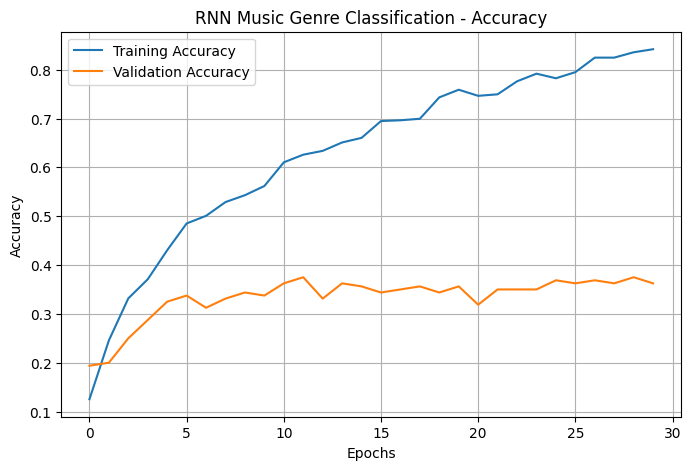

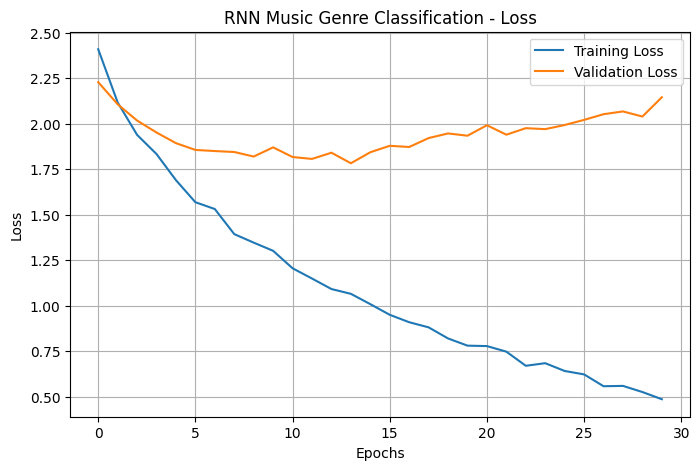

In [3]:
import os
import numpy as np
import librosa
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report

# Dataset path updated to the downloaded Kaggle dataset path
path = "/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original"

# Parameters
num_mfcc = 40
max_len = 130

X = []
y = []

# Extract MFCC features
for genre in sorted(os.listdir(path)):

    genre_path = os.path.join(path, genre)

    if not os.path.isdir(genre_path):
        continue

    for file in os.listdir(genre_path):

        if file.endswith(".wav"):

            file_path = os.path.join(genre_path, file)

            try:
                audio, sr = librosa.load(
                    file_path,
                    sr=22050,
                    duration=30
                )

                mfcc = librosa.feature.mfcc(
                    y=audio,
                    sr=sr,
                    n_mfcc=num_mfcc
                )

                # Select 130 time steps
                indices = np.linspace(
                    0, mfcc.shape[1] - 1, max_len
                ).astype(int)

                mfcc = mfcc[:, indices]

                # Transpose for RNN input
                X.append(mfcc.T)
                y.append(genre)

            except Exception as e:
                print("Error:", file_path, e)

# Convert into arrays
X = np.array(X)
y = np.array(y)

print("Feature Shape:", X.shape)

# Encode genre labels
encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Genres:", encoder.classes_)

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalize MFCC features
scaler = StandardScaler()

X_train = scaler.fit_transform(
    X_train.reshape(-1, num_mfcc)
).reshape(-1, max_len, num_mfcc)

X_test = scaler.transform(
    X_test.reshape(-1, num_mfcc)
).reshape(-1, max_len, num_mfcc)

# Build RNN model
model = models.Sequential([
    layers.Input(shape=(max_len, num_mfcc)),

    layers.SimpleRNN(64, activation='tanh'),

    layers.Dropout(0.3),

    layers.Dense(64, activation='relu'),

    layers.Dense(
        len(encoder.classes_),
        activation='softmax'
    )
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32
)

# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy * 100, "%")

# Predict genres
y_pred = np.argmax(model.predict(X_test), axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
))

# Plot Accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title("RNN Music Genre Classification - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title("RNN Music Genre Classification - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [4]:

print("Test Accuracy:", accuracy * 100, "%")


Test Accuracy: 36.000001430511475 %
